### M2 SID 2026-2027
<div align="center">
  <h2 style="font-size: 36px;"><b>TP n°2 : régression</b></h2>
</div>

 
<div align="center">
  <h2 style="font-size: 30px;"><b>Par Muriel Visani</b></h2>
</div>


L'objectif principal de ce TP est de vous donner quelques rappels de pandas / scikit-learn, matplotlib, et de la régression. En insistant sur l'évaluation des performances et la validation de modèles.
Ce sont vraiment les bases...
En tant qu'étudiant de M2 SID, vous devez obligatoirement être capables de faire ce TP avec seulement l'aide de Python. Sinon, vous ne serez jamais même capable de  corriger l'IA sur des tâches de base, et alors pourquoi une entreprise aurait-elle intérêt à vous embaucher ???

L'usage de l'IA générative (Gemini etc.) est donc **interdit** pendant ce TP. Si vous utilisez une IA générative, votre note de TP sera divisée par 4. 

### Q1

Make the basic configuration of our Python notebook in build, visualize and evaluate your machine learning models: pandas, numpy, scikit-lean, seaborn and matplotlib.

In [53]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as sk
import numpy as np

## Lecture des données

### Q2

Load the data in the file "Data.xlsx". 

NOTE: In this lab work, we will focus on the link between the variables `X` (on one hand) and `Y1`, `Y2`, `Y3` and `Y4` (on the other hand). We will **not** study the link between 'Y1' and 'Y2' for instance.

In [ ]:
# load excel file 
df = pd.read_excel('Data.xlsx')


## Visualizing the links between X and the Ys

### Q3

Draw (in one single plot) the values of the variables `Y1`, `Y2`, `Y3` and `Y4` as a function of the variable `X` (4 curves to draw in one single plot). 

In [ ]:
df.columns

In [30]:
Y_columns = ['Y1(i)', 'Y2(i)', 'Y3(i)', 'Y4(i)']

In [25]:
df[Y_columns]

,Y1(i),Y2(i),Y3(i),Y4(i)
0,1.496476,5.525446,2.497729,3.198039
1,1.461416,5.200333,2.508925,3.480300
2,1.404312,4.989257,2.520120,3.514334
3,1.718453,4.939891,2.531316,3.274860
4,1.565779,4.768606,2.542512,2.986224
...,...,...,...,...
95,4.981848,4.823833,3.561319,3.709241
96,4.662207,4.789406,3.572514,4.815265
97,4.239036,4.966183,3.583710,5.717733
98,4.837929,5.154212,3.594906,6.342711


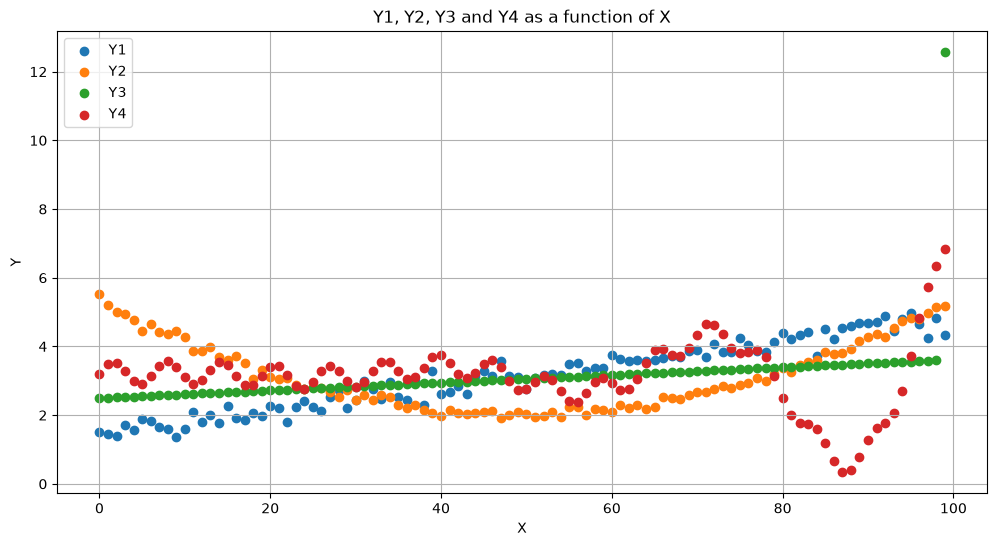

In [39]:
plt.figure(figsize=(12, 6))
plt.scatter(df['X(i)'], df['Y1(i)'], label='Y1')
plt.scatter(df['X(i)'], df['Y2(i)'], label='Y2')
plt.scatter(df['X(i)'], df['Y3(i)'], label='Y3')
plt.scatter(df['X(i)'], df['Y4(i)'], label='Y4')

plt.xlabel('X')
plt.ylabel('Y')
plt.title('Y1, Y2, Y3 and Y4 as a function of X')
plt.legend()
plt.grid()

plt.show()

## Pearson's correlation coefficient

Recall : $\rho=\frac{\sum(X_i-\bar X)(Y_i-\bar Y)}{\sigma_X\sigma_Y}=\frac{\sum X_iY_i-\bar X\bar Y}{\sigma_X\sigma_Y}$.

### Q4

Compute the 4 Pearson's correlation coefficients between the variable `X` (on one hand) and the variables `Y1`, `Y2`, `Y3`, `Y4` (on the other hand).

In [34]:
pr_correlations = [] 
for y_col in Y_columns:
    correlation = df['X(i)'].corr(df[y_col])
    pr_correlations.append(correlation)


In [35]:
# view 
pr_correlations

[np.float64(0.9767957090744442),
 np.float64(-0.009893032594189425),
 np.float64(0.4769555880514441),
 np.float64(-0.07443386626016965)]

## Spearman's correlation coefficient

### Q5

<font color='red'> Point de validation 1 : une fois que vous aurez terminé cette question, appelez la prof et attendez-vous à répondre à des questions sur votre réponse (à voix basse)  <img src="buttonValidate.gif"> 

What are the main differences between the Pearson's and Spearman's correlation coefficients? Explain in a few simple words.



pearson is used for continuous numerical variables while spearman is used for variable having a ranked order (ordinal)
pearson is used for normal distributions which makes it more sensible to outliers compared to spearman( more robust because of ranks)
for spearman it needs to follow the same trend or else (if convex) it will sum up to 0
whereas pearson can capture that 



### Q5

Compute the 4 Spearman's correlation coefficients between the variable `X` (on one hand) and the variables `Y1`, `Y2`, `Y3`, `Y4` (on the other hand).

In [ ]:
#  computing spearman correlations between X and Y_columns
sp_correlations = []
for y_col in Y_columns:
    correlation = df['X(i)'].corr(df[y_col], method='spearman')
    sp_correlations.append(correlation)


In [37]:
sp_correlations

[np.float64(0.9786978697869786),
 np.float64(-0.0012961296129612961),
 np.float64(0.9999999999999999),
 np.float64(-0.06807080708070806)]

### Q6

<font color='red'> Point de validation 2 : une fois que vous aurez terminé cette question, appelez la prof et attendez-vous à répondre à des questions sur vos commentaires <img src="buttonValidate.gif"> 
    
    
Using the 8 coefficients that you calculated at questions 3 and 4 as well as the plot of question 2, comment on the nature of the link between the variables `X` and `Yi`, where $i\in\{1,2,3,4\}$ (linear, non-linear, monotonous, non-monotonous). 
Say as much as you can about that, as well as the absolute and relative values of both Pearson's and Spearman's correlations.

Spearman correlations:
(X,Y1): 0.97 theres a linear positive monotonic relatioship
(X,Y2): -0.001 curve goes down then up no monotonic relationship
(X,Y3): 0.99 positive linear monotonic
(X,Y4): -0.068 up and down  no monotonic

Pearson correlations:
(X,Y1): 0.97 
(X,Y2): -0.00
(X,Y3): 0.47
(X,Y4): -0.07



Regardons donc de plus près chacune des courbes...

## Regression

In this section, we will compute the best type of regression between `X` and the four variables `Yi`.

## Regression of Y1 as a function of X

### Q7

Plot `Y1` as a function of `X` (scatterplot, same as in question 2, but this time with only Y1).

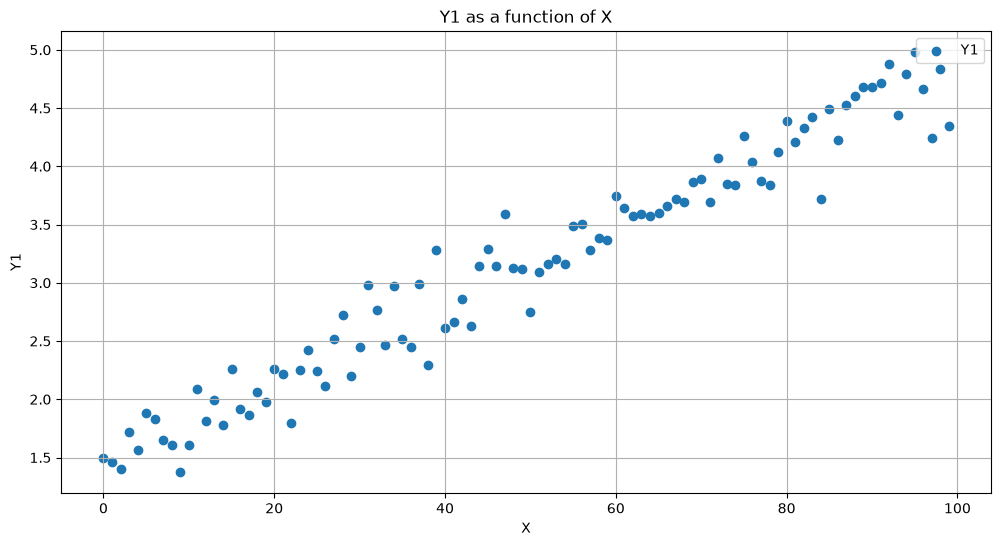

In [40]:
plt.figure(figsize=(12, 6))
plt.scatter(df['X(i)'], df['Y1(i)'], label='Y1')

plt.xlabel('X')
plt.ylabel('Y1')
plt.title('Y1 as a function of X')
plt.legend()
plt.grid()

plt.show()

It looks like a straight line model could fit quite well this data... 

So, if we want to build a model in order to estimate the `Y1` from the `X`, we would like to build a model like the straight line hereafter:
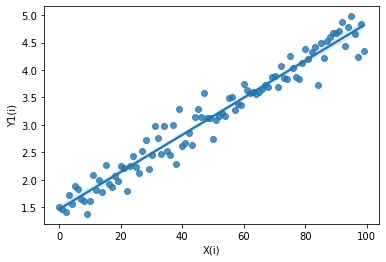

This is **LINEAR REGRESSION**: "LINEar" as in "STRAIGHT LINE".

IMPORTANT NOTE: Here we are inferring the response variable (`Y1`) from only ONE explanatory variable (`X`), so we can visualize the model as a straight line.

If we had 2 explanatory variables, then linear regression's model would be a 2D plane...

With more than 3 explanatory variables, the model would be an hyperplane (much more difficult to visualize, but still linear)...

He, we want a model (line) that fits well the data, like the one above, and not other models like the ones in red below:
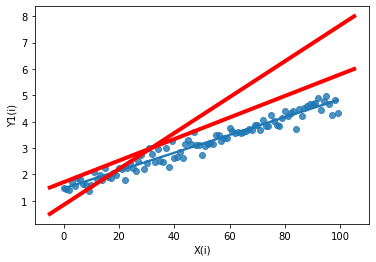

In order to find the "best" regression line amongst all possible straight lines in the (`X`, `Y1`) plane, we need to find the one that minimizes the distances between the data and the regression line (such distances are called errors).

In this case, we want to minimize the Residual Sum of Squares (RSS), which is explained hereafter (explanations taken from Wikipedia) :
<img src="regression.png"> 


For that purpose and because this problem is very simple, we can use the OLS (Ordinary Least Squares) method.  



### Q8

<font color='red'> Point de validation 3 : une fois que vous aurez terminé cette question, appelez la prof et attendez-vous à répondre à des questions sur votre code et vos commentaires (à voix basse) <img src="buttonValidate.gif"> 
    
Apply Linear Regression, using OLS, to this problem, and give the two coefficients that you obtain ($\hat{\alpha}$ and $\hat{\beta}$ using the notations above).

For that purpose, please use BOTH the function LinearRegression from the sklearn.linear_model library and the statsmodels.api function called OLS, and compare the two models obtained (in terms of coefficient, intercept and AIC). What do you notice?

    


In [49]:
# applying LinearRegression and OLS regression, display the coefficients alpha and beta: for X(i) and Y1(i)
from sklearn import linear_model
import statsmodels.api as sm
from statsmodels.api import OLS

# LinearRegression
lm = linear_model.LinearRegression()
lm.fit(df[['X(i)']], df['Y1(i)'])
print("Linear Regression****")
print(f"Alpha (intercept): {lm.intercept_}")
print(f"Beta (coefficient): {lm.coef_[0]}")
print("\n")

# OLS regression
X = df[['X(i)']]
X = sm.add_constant(X)  # adding intercept term
y = df['Y1(i)']
model = OLS(y, X)
results = model.fit()
print("OLS Regression****") 
# print(results.summary())
# from results print only the coefficients alpha and beta and the intercept term
print(f"Alpha (intercept): {results.params['const']}")
print(f"Beta (coefficient): {results.params['X(i)']}")




Linear Regression****
Alpha (intercept): 1.46656770148342
Beta (coefficient): 0.0338388879213409


OLS Regression****
Alpha (intercept): 1.466567701483421
Beta (coefficient): 0.03383888792134089


In [ ]:
# aic value for lr
# we need to define a function to calculate AIC for LR, we need to get two parameters:
# K is the number of model parameters (the number of variables in the model plus the intercept).
# Log-likelihood is a measure of model fit. The higher the number, the better the fit. This is usually obtained from statistical output.
def calculate_aic(n, rss, k):
    aic = n * np.log(rss / n) + 2 * k
    return aic

AIC for OLS: -20.406379226693872


In [ ]:
# apply the calculate_aic to our lm model, k=2 because we have alpha and beta

# we use the residuals from the lm model predictions
residuals = df['Y1(i)'] - lm.predict(df[['X(i)']])
rss = np.sum(residuals**2)

aic_value_lm = calculate_aic(n=len(residuals), rss=rss, k=2) 
print(f"AIC for LM: {aic_value_lm}")


AIC for LM: -304.1940858676285


In [57]:
# comparing the two models' performances: coefficient, intercept and AIC
# get the aic value from the OLS results
aic_value = results.aic
print(f"AIC for OLS: {aic_value}")

AIC for OLS: -20.406379226693872


### Q9

Plot the data together with the regression line that you just obtained (with the regression line's equation). Do you think that it's a good fit?

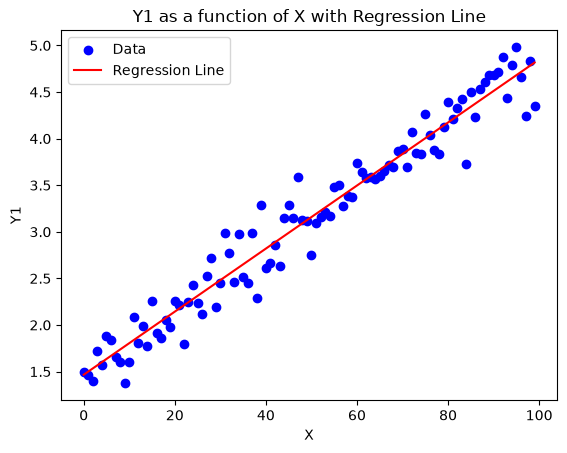

In [58]:
# we plot the Y1 data with the regression line from the linear regression model (since its the same coefficients for both of lm and OLS)
plt.scatter(df['X(i)'], df['Y1(i)'], color='blue', label='Data')
plt.plot(df['X(i)'], lm.predict(df[['X(i)']]), color='red', label='Regression Line')
plt.xlabel('X')
plt.ylabel('Y1')
plt.title('Y1 as a function of X with Regression Line')
plt.legend()
plt.show()

### Q10

We are going to check if it is really a good fit using some measures.

The first measure is **Adjusted R-squared**, which is the the proportion of the variance in the response variable that can be explained by the predictor variables in a linear regression model. So, its value is between 0 and 1, and the higher its value, the better. 

Note: Actually, if the sample size is small, Adjusted R-squared might be slightly negative if the explanatory variable is not linearly predictive of the response variable.

For more details about that measure, please check: https://www.statology.org/adjusted-r-squared-in-python/

    a. Give the value of the Adjusted R-squared for this model and your data. Now, do you think that your model is good?


In this case, it is very simple to choose the best linear regression model, because there is only one possibility (1 explanatory variable, 1 response variable). 

But, if we have more than 1 explanatory variable (let's say X1 and X2 instead of just X), then we have several possible models, with different sets of explanatory variables (X1 -> Y1, (X1,X2) -> Y1 or X2 -> Y1 in our example).

In order to compare such different models and select the best one, then we need to use a measure that takes into account parsimony of the models. Most people use either AIC (Akaike information criterion (AIC)) or SBC. 
We will consider AIC. Please read https://www.statology.org/aic-in-python/.

    b. Compute the AIC of the model and give it. Does this criterion give you any idea of the quality of the model (when you consider this criterion only)? In which cases is it useful?

### Q11

<font color='red'> Point de validation 4 : une fois que vous aurez terminé cette question, appelez la prof et attendez-vous à répondre à des questions sur votre code et vos commentaires (à voix basse) <img src="buttonValidate.gif"> 
    
In the original dataset, we had one observation for which we had only the value of X, and not the value of Y1.

    a. Using your model, please ESTIMATE the value of Y1, for X=150, using the predict() function.

    b. Verify that you obtain exactly the same result with the equation of your model (line).
    
    c. Verify, with a plot, that it visually fits the model.

## Regression of Y2 as a function of X

### Q12 
Plot `Y2` as a function of `X` (scatterplot, same as in question 2, but this time with only Y2).

### Q13

In this case, given the parabolic shape of the scatterplot, the linear regression will obviously not be enough to correcly fit our data.

We'll need a quadratic shape (polynomial of order 2).

But, first of all, we will naïvely use a simple linear regression and verify that it is not good.

    a. Compute the Linear Regression model for X -> Y2.
    
    b. Plot this model together with the data.
    
    c. Which evaluation measure should you use to quantify how good (or bad) is your model? (Adjusted-R-squared or AIC)?
    
    d. Compute both quality measure (Adjusted-R-squared and AIC).
    
    e. Quantatively, is it a good model given our data?
    

Now, you'll apply quadratic regression. You actually can use the same LinearRegression method, but AFTER transforming the vector X into a vector (X, X^2). 

### Q14

You can use the Pipeline function so as to first make the transformation, then apply linear regression on it. Give the coefficients of the quadratic regression.

Hint: To make the transformation from the vector X into the vector (X, X^2), you can use PolynomialFeatures from sklearn.preprocessing.

### Q15

Using the coefficients of the quadratic regression, plot the model together with the data. Does it seem like a good model?

### Q16

<font color='red'> Point de validation 5 : une fois que vous aurez terminé cette question, appelez la prof et attendez-vous à répondre à des questions sur votre réponse (à voix basse)  <img src="buttonValidate.gif">

    a. Compute the relevant quality measure (Adjusted-R-squared or AIC) to determine if it's a good model, or not, and compare it with the linear regression model that you obtained on the same data (in question Q13).
    
    b. Is the quadratic model a good model, given our data?

## Regression of Y3 as a function of X

### Q17

Plot `Y3` as a function of `X` (scatterplot, same as in question 2, but this time with only Y3). Observe that there is an outlier.

We wonder if the outlier will have too much influence on the regression model, or not.

### Q18

Apply linear regression on the full dataset (including the outlier), and plot the model.


### Q19

<font color='red'> Point de validation 6 : une fois que vous aurez terminé cette question, appelez la prof et attendez-vous à répondre à des questions sur votre réponse (à voix basse)  <img src="buttonValidate.gif">

    a. Delete the outlier (first, of course, you have to spot it), and run linear regression, and plot the model together with the data. Is the model better this time (without the outlier)?
    
    b. Compute the relevant quality measure (Adjusted-R-squared or AIC) to determine if it's a good model, or not.
    
    c. Did the outlier have a lot of impact on the regression model?
    
    d. Which techniques do you know for spotting outliers?

## Regression of Y4 as a function of X

As we will see in this section, the case of Y4 is more complex than the other 3 cases.

### Q20

Plot `Y4` as a function of `X` (scatterplot, same as in question 2, but this time with only Y4). Observe how complex is the link this time.

Clearly, here the regression model is way more complex than just linear or polynomial.

Here, we are going to use a SVR (Support Vector Regression). The idea is quite similar to SVM, but for regression. But, SVR requires many settings.


### Q21

Explain (give comments about) the piece of code given hereafter: what does it do? What do the three parameters of SVR correspond to? What do the 3 curves shown in the plot correspond to (comment on the quality of the three models as you can see from the plots).

### Q22

<font color='red'> Point de validation 7 : une fois que vous aurez terminé cette question, appelez la prof et attendez-vous à répondre à des questions sur votre réponse (à voix basse)  <img src="buttonValidate.gif">

    a. Compute the sum of squared errors of each three models.
    
    b. Which model do you think is best for this problem (provided that, of course, you want to further use this model for predictions)?



# Real Data: DataSaurus

<font color='red'> Point de validation 8 : une fois que vous aurez terminé cette question, appelez la prof et attendez-vous à répondre à des questions sur votre réponse (à voix basse)  <img src="buttonValidate.gif">
    
**Work to be done** : apply the same kind of study on the data from the file `DatasaurusDozen.xlsx`, using BOTH SVR and regression trees. Create all the cells that you will need for this study, and fill them in, in the rest of this notebook.